# 🚀 Canlı Sinyallerden Kâr/Zarar (PnL) Simülasyonu

Bu notebook, `logs/multi_signals_*.csv` dosyasındaki AL-SAT-BEKLE sinyallerini kronolojik olarak okur. İşlemleri eşleştirerek Entry (Giriş) ve Exit (Çıkış) fiyatlarını bulur ve **komisyonlar düşüldükten sonra** hangi altcoinde ne kadar kâr/zarar edildiğini hesaplar.

In [183]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)

### 1. Canlı Sinyal Verisini Yükleme

In [184]:
# Tüm multi_signals dosyalarını (VM dahil) bul ve tek bir verisetinde birleştir
csv_files = glob.glob('../logs/multi_signals_*.csv')

if csv_files:
    print(f"✅ {len(csv_files)} adet sinyal dosyası bulundu. Birleştiriliyor...")
    df_list = []
    for file in csv_files:
        temp_df = pd.read_csv(file)
        df_list.append(temp_df)
        print(f"   -> Okundu: {os.path.basename(file)} ({len(temp_df)} satır)")
    
    # Tüm dataları birleştir
    df = pd.concat(df_list, ignore_index=True)
    df['Zaman'] = pd.to_datetime(df['Zaman'])
    
    # Kronolojik olarak sırala ve olası tekrarları (duplicate) temizle
    df = df.sort_values(by=['Sembol', 'Zaman']).drop_duplicates()
    
    print(f"\n✅ Tüm veriler kronolojik olarak birleştirildi! Toplam Sinyal: {len(df)}")
    display(df.head())
else:
    print("❌ ../logs/ dizininde multi_signals CSV dosyası bulunamadı.")
    df = pd.DataFrame()

✅ 2 adet sinyal dosyası bulundu. Birleştiriliyor...
   -> Okundu: multi_signals_2026-10-01-vm.csv (1144 satır)
   -> Okundu: multi_signals_2026-10-01.csv (341 satır)

✅ Tüm veriler kronolojik olarak birleştirildi! Toplam Sinyal: 1485


,Zaman,Sembol,Fiyat,Macro_OBI,CVD_1m,Sinyal_Yonu
197,2026-10-01 21:46:57,1INCHUSDT,0.101625,-0.4015,-2471.0,🔴 SAT (SHORT)
478,2026-10-01 23:39:55,1INCHUSDT,0.102265,0.1508,12077.0,⚪ BEKLE
1165,2026-10-01 18:58:28,AAVEUSDT,168.180000,-0.4323,-567.7,🔴 SAT (SHORT)
1195,2026-10-01 19:16:41,AAVEUSDT,166.715000,0.1515,-272.9,⚪ BEKLE
1317,2026-10-01 21:19:06,AAVEUSDT,168.640000,-0.5008,-5.6,🔴 SAT (SHORT)


### 2. Sinyalleri Gerçek İşlemlere (Trade) Dönüştürme Motoru

In [185]:
trades = []
COMMISSION_ROUND_TRIP = 0.00032 # Limit(Maker) komisyonu (Giris %0.016 + Cikis %0.016)

if not df.empty:
    # Her bir Altcoin icin ayri ayri simule et
    for symbol, group in df.groupby('Sembol'):
        position = 0 # 1 = LONG, -1 = SHORT, 0 = NAKIT
        entry_price = 0.0
        entry_time = None
        
        for idx, row in group.iterrows():
            sig = row['Sinyal_Yonu']
            price = float(row['Fiyat'])
            time = row['Zaman']
            
            if position == 0:
                if 'AL (LONG)' in sig:
                    position = 1
                    entry_price = price
                    entry_time = time
                elif 'SAT (SHORT)' in sig:
                    position = -1
                    entry_price = price
                    entry_time = time
            
            elif position == 1:
                if 'BEKLE' in sig or 'SAT' in sig:
                    # LONG Cikis
                    brut_pnl_pct = (price - entry_price) / entry_price
                    net_pnl_pct = brut_pnl_pct - COMMISSION_ROUND_TRIP
                    trades.append({"Sembol": symbol, "Yon": "LONG", "Giris_Zaman": entry_time, "Cikis_Zaman": time, 
                                   "Entry_Fiyat": entry_price, "Exit_Fiyat": price, "Net_PnL_%": net_pnl_pct * 100})
                    
                    if 'SAT' in sig:
                        position = -1; entry_price = price; entry_time = time
                    else:
                        position = 0
                        
            elif position == -1:
                if 'BEKLE' in sig or 'AL' in sig:
                    # SHORT Cikis
                    brut_pnl_pct = (entry_price - price) / entry_price
                    net_pnl_pct = brut_pnl_pct - COMMISSION_ROUND_TRIP
                    trades.append({"Sembol": symbol, "Yon": "SHORT", "Giris_Zaman": entry_time, "Cikis_Zaman": time, 
                                   "Entry_Fiyat": entry_price, "Exit_Fiyat": price, "Net_PnL_%": net_pnl_pct * 100})
                    
                    if 'AL' in sig:
                        position = 1; entry_price = price; entry_time = time
                    else:
                        position = 0

    df_trades = pd.DataFrame(trades)
    if not df_trades.empty:
        print(f"✅ {len(df_trades)} adet kapanmis islem olusturuldu.")
        display(df_trades.head())
    else:
        print("Henuz kapanmis (Giris ve Cikisi tamamlanmis) bir islem yok.")

✅ 712 adet kapanmis islem olusturuldu.


,Sembol,Yon,Giris_Zaman,Cikis_Zaman,Entry_Fiyat,Exit_Fiyat,Net_PnL_%
0,1INCHUSDT,SHORT,2026-10-01 21:46:57,2026-10-01 23:39:55,0.101625,0.102265,-0.661766
1,AAVEUSDT,SHORT,2026-10-01 18:58:28,2026-10-01 19:16:41,168.180000,166.715000,0.839090
2,AAVEUSDT,SHORT,2026-10-01 21:19:06,2026-10-01 21:36:07,168.640000,169.785000,-0.710961
3,AAVEUSDT,LONG,2026-10-01 22:41:19,2026-10-01 23:05:44,167.835000,170.085000,1.308602
4,AAVEUSDT,LONG,2026-10-02 05:50:24,2026-10-02 06:09:49,180.955000,181.405000,0.216681


### 3. Altcoinlere Göre Toplam PnL (Kâr/Zarar) Analizi

C:\Users\ulker\AppData\Local\Temp\ipykernel_5172\1636945191.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pnl_by_symbol, x='Sembol', y='Net_PnL_%', palette=colors)


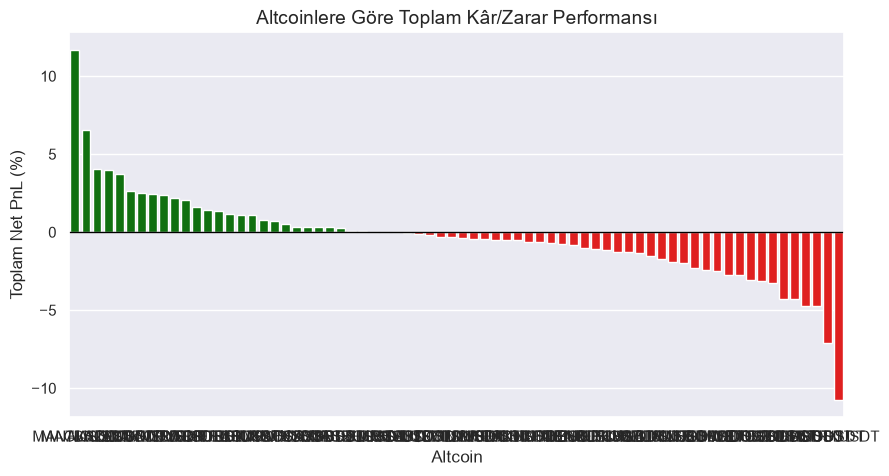

,Sembol,Net_PnL_%
37,MANAUSDT,11.688503
36,MAGICUSDT,6.515518
57,TIAUSDT,4.073837
9,BATUSDT,3.958205
51,SOLUSDT,3.758041
...,...,...
11,BNBUSDT,-4.283359
29,IOTAUSDT,-4.722247
32,LDOUSDT,-4.736428
40,NEOUSDT,-7.122513


In [186]:
if 'df_trades' in locals() and not df_trades.empty:
    pnl_by_symbol = df_trades.groupby('Sembol')['Net_PnL_%'].sum().reset_index()
    pnl_by_symbol = pnl_by_symbol.sort_values(by='Net_PnL_%', ascending=False)
    
    plt.figure(figsize=(10, 5))
    colors = ['green' if x > 0 else 'red' for x in pnl_by_symbol['Net_PnL_%']]
    sns.barplot(data=pnl_by_symbol, x='Sembol', y='Net_PnL_%', palette=colors)
    
    plt.title('Altcoinlere Göre Toplam Kâr/Zarar Performansı', fontsize=14)
    plt.xlabel('Altcoin')
    plt.ylabel('Toplam Net PnL (%)')
    plt.axhline(0, color='black', linestyle='-', linewidth=1)
    plt.show()
    
    display(pnl_by_symbol)

### 4. Başarı Oranı (Win Rate) ve Risk Tablosu

In [187]:
if 'df_trades' in locals() and not df_trades.empty:
    win_rate = (len(df_trades[df_trades['Net_PnL_%'] > 0]) / len(df_trades)) * 100
    avg_win = df_trades[df_trades['Net_PnL_%'] > 0]['Net_PnL_%'].mean()
    avg_loss = df_trades[df_trades['Net_PnL_%'] <= 0]['Net_PnL_%'].mean()
    
    print("="*40)
    print(f"📊 GENEL STRATEJİ PERFORMANSI")
    print("="*40)
    print(f"Toplam Kapanmış İşlem : {len(df_trades)}")
    print(f"Genel Başarı Oranı    : %{win_rate:.2f}")
    print(f"Ortalama Kâr (Win)    : %{avg_win:.3f}")
    print(f"Ortalama Zarar (Loss) : %{avg_loss:.3f}")
    print(f"Toplam Net Getiri     : %{df_trades['Net_PnL_%'].sum():.3f}")
    print("="*40)

📊 GENEL STRATEJİ PERFORMANSI
Toplam Kapanmış İşlem : 712
Genel Başarı Oranı    : %39.47
Ortalama Kâr (Win)    : %0.389
Ortalama Zarar (Loss) : %-0.310
Toplam Net Getiri     : %-24.064


In [190]:
df_trades[df_trades['Sembol'] == 'MANAUSDT'].sort_values(by='Giris_Zaman', ascending=False).head(10)

,Sembol,Yon,Giris_Zaman,Cikis_Zaman,Entry_Fiyat,Exit_Fiyat,Net_PnL_%
468,MANAUSDT,LONG,2026-10-02 06:48:49,2026-10-02 08:13:08,0.089530,0.100865,12.628561
467,MANAUSDT,LONG,2026-10-02 00:32:26,2026-10-02 01:27:40,0.089075,0.088360,-0.834694
466,MANAUSDT,LONG,2026-10-01 23:24:27,2026-10-01 23:52:55,0.088600,0.088535,-0.105363


### 5. Sembol (Tahta) Bazlı Detaylı Karne (Tahta Seçimi İçin)

Aşağıdaki tablo, stratejinin hangi coinlerde gerçekten çalıştığını, hangilerinde ise manipülasyona kurban gittiğini tespit etmemizi sağlar. Tablo **Net PnL**'e göre sıralanmıştır.

In [189]:
if 'df_trades' in locals() and not df_trades.empty:
    stats = []
    for sym, group in df_trades.groupby('Sembol'):
        toplam_islem = len(group)
        kazananlar = group[group['Net_PnL_%'] > 0]
        kaybedenler = group[group['Net_PnL_%'] <= 0]
        
        win_rate = (len(kazananlar) / toplam_islem) * 100
        net_pnl = group['Net_PnL_%'].sum()
        avg_win = kazananlar['Net_PnL_%'].mean() if not kazananlar.empty else 0
        avg_loss = kaybedenler['Net_PnL_%'].mean() if not kaybedenler.empty else 0
        
        stats.append({
            'Sembol': sym,
            'İşlem Sayısı': toplam_islem,
            'Win Rate (%)': win_rate,
            'Net PnL (%)': net_pnl,
            'Ort. Kâr (%)': avg_win,
            'Ort. Zarar (%)': avg_loss
        })
        
    df_stats = pd.DataFrame(stats)
    df_stats = df_stats.sort_values(by='Net PnL (%)', ascending=False).reset_index(drop=True)
    
    # Gorsel olarak zenginlestirilmis tablo
    styled_table = (df_stats.style
                    .background_gradient(cmap='RdYlGn', subset=['Net PnL (%)', 'Win Rate (%)'])
                    .format({'Win Rate (%)': '{:.1f}', 'Net PnL (%)': '{:.3f}', 
                             'Ort. Kâr (%)': '{:.3f}', 'Ort. Zarar (%)': '{:.3f}'}))
    
    display(styled_table)
else:
    print("Analiz edilecek kapalı işlem bulunamadı.")

,Sembol,İşlem Sayısı,Win Rate (%),Net PnL (%),Ort. Kâr (%),Ort. Zarar (%)
0,MANAUSDT,3,33.3,11.689,12.629,-0.470
1,MAGICUSDT,5,60.0,6.516,2.352,-0.270
2,TIAUSDT,9,44.4,4.074,1.539,-0.417
3,BATUSDT,1,100.0,3.958,3.958,0.000
4,SOLUSDT,7,71.4,3.758,0.813,-0.154
5,ZECUSDT,12,75.0,2.640,0.322,-0.086
6,AVAXUSDT,18,66.7,2.498,0.424,-0.432
7,ONTUSDT,2,100.0,2.427,1.213,0.000
8,AAVEUSDT,5,80.0,2.398,0.777,-0.711
9,OPUSDT,5,40.0,2.210,1.843,-0.492
